In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import xraylib

In [2]:
# Specify the path to your FITS file
fits_file = 'RXTE-ASM_BeppoSAX-WFC_catalog_new.fits' 

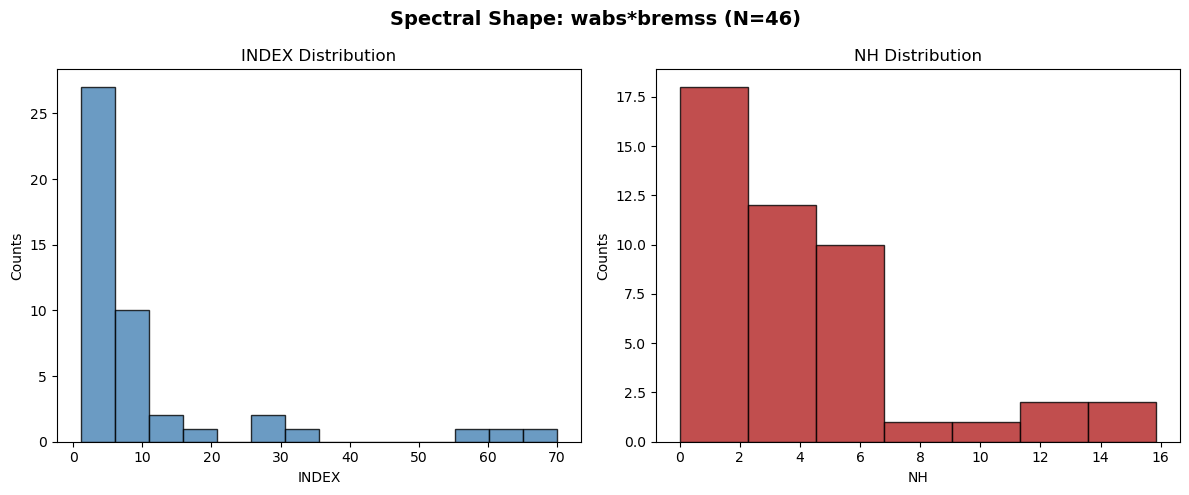

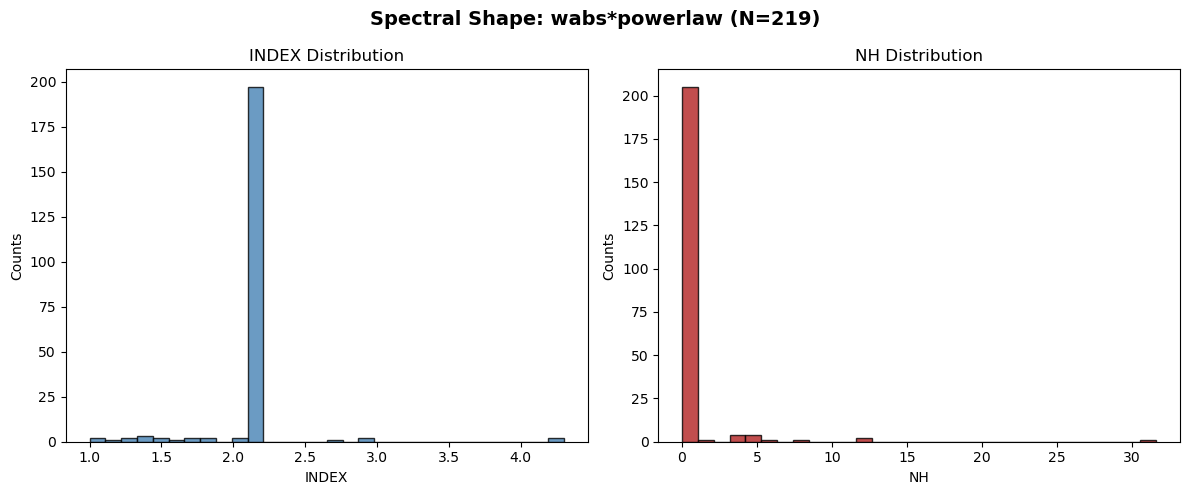

In [3]:



# Open the FITS file and extract the data table (assumed to be in the first extension)
with fits.open(fits_file) as hdul:
    data = hdul[1].data

# Extract the relevant columns
formulas = data['FORMULA']
indexes = data['INDEX']
nhs = data['NH']

# FITS string arrays can sometimes contain bytes or trailing spaces.
# Convert to standard strings and strip whitespace to ensure clean matching.
if isinstance(formulas[0], (bytes, np.bytes_)):
    formulas = np.array([f.decode('utf-8').strip() for f in formulas])
else:
    formulas = np.array([str(f).strip() for f in formulas])

# Identify the unique spectral shapes
unique_formulas = np.unique(formulas)

# Generate plots for each unique spectral shape
for shape in unique_formulas:
    if not shape:  # Skip empty string formulas if any exist
        continue
        
    # Create a mask for the current spectral shape
    mask = (formulas == shape)
    
    # Filter the INDEX and NH fields using the mask, dropping any NaN values
    current_indexes = indexes[mask]
    current_indexes = current_indexes[~np.isnan(current_indexes)]
    
    current_nhs = nhs[mask]
    current_nhs = current_nhs[~np.isnan(current_nhs)]
    
    # Set up the figure with 2 subplots side-by-side
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f'Spectral Shape: {shape} (N={np.sum(mask)})', fontsize=14, fontweight='bold')
    
    # Plot the INDEX histogram (density=False ensures it is not normalized)
    ax1.hist(current_indexes, bins='auto', density=False, color='steelblue', edgecolor='black', alpha=0.8)
    ax1.set_title('INDEX Distribution')
    ax1.set_xlabel('INDEX')
    ax1.set_ylabel('Counts')
    
    # Plot the NH histogram
    ax2.hist(current_nhs, bins='auto', density=False, color='firebrick', edgecolor='black', alpha=0.8)
    ax2.set_title('NH Distribution')
    ax2.set_xlabel('NH')
    ax2.set_ylabel('Counts')
    
    plt.tight_layout()
    plt.show()

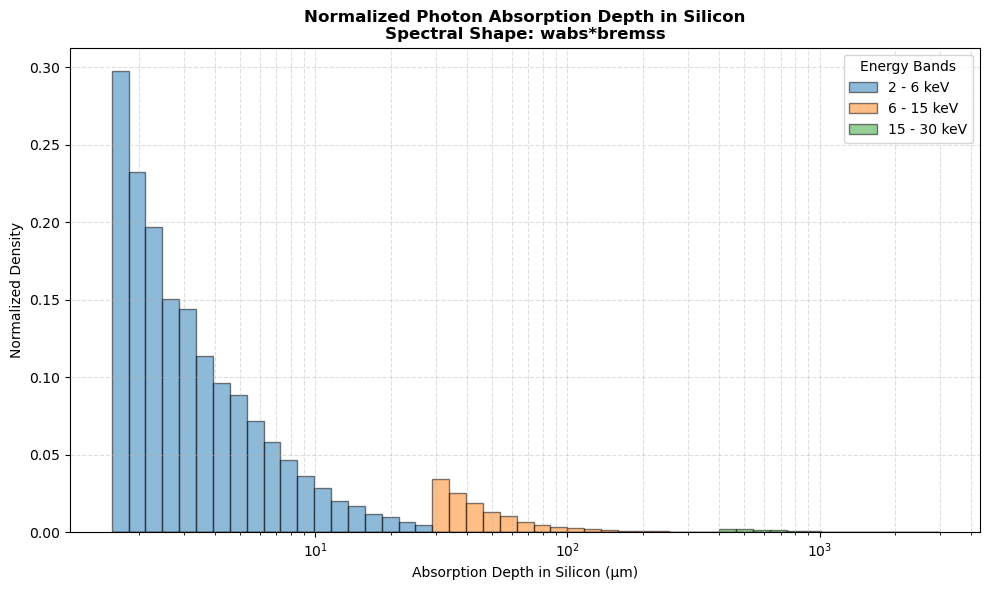

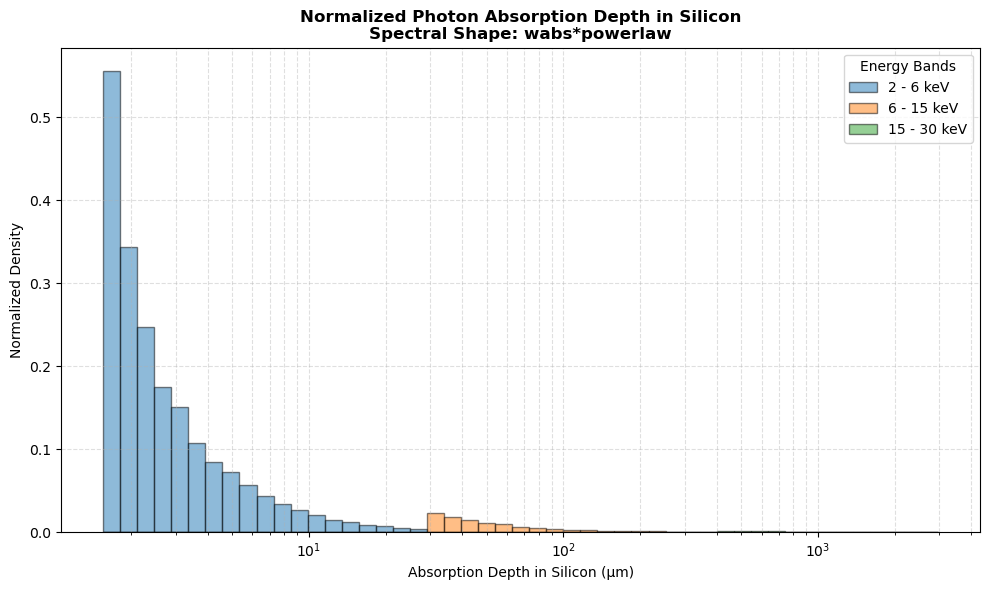

In [4]:
fits_file = 'RXTE-ASM_BeppoSAX-WFC_catalog_new.fits'

with fits.open(fits_file) as hdul:
    data = hdul[1].data

if isinstance(data['FORMULA'][0], (bytes, np.bytes_)):
    formulas = np.array([f.decode('utf-8').strip() for f in data['FORMULA']])
else:
    formulas = np.array([str(f).strip() for f in data['FORMULA']])

unique_formulas = np.unique(formulas)
unique_formulas = unique_formulas[unique_formulas != ""] 

rho_si = 2.329  
bands = [(2, 6), (6, 15), (15, 30)]
band_colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for shape in unique_formulas:
    mask = (formulas == shape)
    
    energies = data['ENERGY'][mask]
    spectra = data['SPECTRUM'][mask]
    
    cumulative_spectrum = np.sum(spectra, axis=0)
    
    mean_energy_edges = np.mean(energies, axis=0)
    energy_centers_keV = (mean_energy_edges[:-1] + mean_energy_edges[1:]) / 2.0
    
    absorption_depths_um = np.zeros_like(energy_centers_keV)
    
    for i, E_keV in enumerate(energy_centers_keV):
        mu_mass = xraylib.CS_Total(14, float(E_keV))
        mu_linear = mu_mass * rho_si
        absorption_depths_um[i] = (1.0 / mu_linear) * 10000
        
    plt.figure(figsize=(10, 6))
    
    # Establish shared logarithmic bins for all bands to ensure proper visual comparison
    min_depth = np.min(absorption_depths_um)
    max_depth = np.max(absorption_depths_um)
    log_bins = np.logspace(np.log10(min_depth), np.log10(max_depth), 50)
    
    # Plot each band
    for (E_min, E_max), color in zip(bands, band_colors):
        # Create a boolean mask for the current energy band
        band_mask = (energy_centers_keV >= E_min) & (energy_centers_keV < E_max)
        
        if np.any(band_mask):
            band_depths = absorption_depths_um[band_mask]
            band_weights = cumulative_spectrum[band_mask]
            
            # Using density=True normalizes the histogram representing a probability density
            plt.hist(band_depths, bins=log_bins, weights=band_weights, density=True, 
                     color=color, edgecolor='black', alpha=0.5, label=f'{E_min} - {E_max} keV')
            
    plt.title(f'Normalized Photon Absorption Depth in Silicon\nSpectral Shape: {shape}', fontweight='bold')
    plt.xlabel('Absorption Depth in Silicon (μm)')
    plt.ylabel('Normalized Density')
    
    plt.xscale('log')
    plt.legend(title="Energy Bands")
    plt.grid(True, which='both', linestyle='--', alpha=0.4)
    
    plt.tight_layout()
    plt.show()

# Weight absorption depths

In [8]:
import numpy as np
from astropy.io import fits
import xraylib

fits_file = 'RXTE-ASM_BeppoSAX-WFC_catalog_new.fits'

with fits.open(fits_file) as hdul:
    data = hdul[1].data

if isinstance(data['FORMULA'][0], (bytes, np.bytes_)):
    formulas = np.array([f.decode('utf-8').strip() for f in data['FORMULA']])
else:
    formulas = np.array([str(f).strip() for f in data['FORMULA']])

unique_formulas = np.unique(formulas)
unique_formulas = unique_formulas[unique_formulas != ""] 

rho_si = 2.329  
detector_thickness_um = 450.0
bands = [(2, 6), (6, 15), (15, 30)]

for shape in unique_formulas:
    mask = (formulas == shape)
    
    energies = data['ENERGY'][mask]
    spectra = data['SPECTRUM'][mask]
    
    # Cumulative incident spectrum
    incident_spectrum = np.sum(spectra, axis=0)
    
    mean_energy_edges = np.mean(energies, axis=0)
    energy_centers_keV = (mean_energy_edges[:-1] + mean_energy_edges[1:]) / 2.0
    
    absorption_depths_um = np.zeros_like(energy_centers_keV)
    for i, E_keV in enumerate(energy_centers_keV):
        mu_mass = xraylib.CS_Total(14, float(E_keV))
        mu_linear = mu_mass * rho_si
        absorption_depths_um[i] = (1.0 / mu_linear) * 10000
        
    print(f"--- Spectral Shape: {shape} ---")
    
    # Pre-calculate the total absorbed photons across the entire spectrum
    total_absorbed_photons = np.sum(incident_spectrum * (1.0 - np.exp(-detector_thickness_um / absorption_depths_um)))
    
    for (E_min, E_max) in bands:
        band_mask = (energy_centers_keV >= E_min) & (energy_centers_keV < E_max)
        
        band_S = incident_spectrum[band_mask]
        band_lambda = absorption_depths_um[band_mask]
        
        # Total photons absorbed inside the 450 um detector for this specific band
        band_absorbed_photons = np.sum(band_S * (1.0 - np.exp(-detector_thickness_um / band_lambda)))
        
        if band_absorbed_photons > 0:
            # Create a high-resolution grid of physical depths from 0 to 450 um
            z_grid = np.linspace(0, detector_thickness_um, 5000)
            
            # Calculate cumulative absorbed photons up to each depth z for the whole band
            cumulative_absorbed_at_z = np.sum(band_S * (1.0 - np.exp(-z_grid[:, None] / band_lambda)), axis=1)
            
            # Find the physical depth z where exactly 50% and 90% of the absorbed photons have interacted
            median_physical_depth = np.interp(0.5 * band_absorbed_photons, cumulative_absorbed_at_z, z_grid)
            p68_physical_depth = np.interp(0.68 * band_absorbed_photons, cumulative_absorbed_at_z, z_grid)
            p95_physical_depth = np.interp(0.95 * band_absorbed_photons, cumulative_absorbed_at_z, z_grid)
            
            percentage = (band_absorbed_photons / total_absorbed_photons) * 100
        else:
            median_physical_depth = np.nan
            p68_physical_depth = np.nan
            p95_physical_depth = np.nan
            percentage = 0.0
            
        print(f"  {E_min:02d}-{E_max:02d} keV Band: Median = {median_physical_depth:6.2f} μm | 68% Pctl = {p68_physical_depth:6.2f} μm | 95% Pctl = {p95_physical_depth:6.2f} μm |Photons = {percentage:5.2f}%")
    print("\n")

--- Spectral Shape: wabs*bremss ---
  02-06 keV Band: Median =   3.29 μm | 68% Pctl =   6.17 μm | 95% Pctl =  26.85 μm |Photons = 90.64%
  06-15 keV Band: Median =  37.92 μm | 68% Pctl =  65.87 μm | 95% Pctl = 222.79 μm |Photons =  9.22%
  15-30 keV Band: Median = 184.52 μm | 68% Pctl = 267.62 μm | 95% Pctl = 417.80 μm |Photons =  0.14%


--- Spectral Shape: wabs*powerlaw ---
  02-06 keV Band: Median =   2.64 μm | 68% Pctl =   4.91 μm | 95% Pctl =  23.24 μm |Photons = 87.46%
  06-15 keV Band: Median =  46.42 μm | 68% Pctl =  82.63 μm | 95% Pctl = 278.13 μm |Photons = 11.67%
  15-30 keV Band: Median = 188.73 μm | 68% Pctl = 272.00 μm | 95% Pctl = 419.09 μm |Photons =  0.88%


